<!-- repo-header -->
# Paper figures

Produces every code-generated figure in the paper, plus Table I. Reads only committed
data, so it runs offline -- no Quantinuum account needed.

| Cell | Output | Paper |
|---|---|---|
| 2 | `fig_R75x4_collated_M32.pdf` | **Fig. 3** -- the dataset, reweighting success, infidelity vs CNOT depth and vs CPU hours |
| 4 | `fig_hardware_4x1024_L1_mid.pdf` | **Fig. 4 + Table I** -- per-branch H2-1 shadow overlap and inferred fidelity |
| 6 | `sweep_P_vs_M.pdf` | **Fig. 5** -- reweighting success probability vs *M* for Haar-random segments |

Each cell is self-contained: it sets its own `BASE`, loads what it needs and emits one
figure, so the cells can be run in any order. `BASE = os.getcwd()`, so run this notebook
**with the repository root as the working directory**.

Figures 1 and 2 (the Q-MERGE Stage-1 circuit diagrams) are drawn in LaTeX in the paper
source and are not generated here.

Re-running a cell writes its PDF **next to the notebook**, not into `figures/`. The
`figures/` directory holds the versions used in the paper, so regenerating never
silently overwrites them.


## Fig. 3 -- Q-MERGE on the 32 x 1024 ultrasound target

Four panels: **(a)** the target dataset, **(b)** the Stage-2 reweighting success
probability before and after classical preconditioning, **(c)** infidelity against
end-to-end CNOT depth and **(d)** against total classical optimisation time, each
comparing Q-MERGE with direct encoding under the same segment-level method (SSO).

Headline numbers printed below the figure: infidelity 3.5e-9 vs 6.2e-3 for direct
encoding at matched CNOT depth, and *P* raised from 0.0098 to 0.3170 by 3 brickwall
preconditioning layers.

  [R75x4_orig] numerical floor from depth 388 -- cut there
  [R75x4_orig] 32 rows, using depth 0..387
  [R75x4_M32_precond_L3] numerical floor from depth 396 -- cut there
  [R75x4_M32_precond_L3] 32 rows, using depth 0..395
  [direct M32] 1954 layers
  cutting every curve at Q-MERGE's deepest point: 10,473
  [Direct encoding] cropped to CNOT depth 10,473: 1739 layers of 1954
  [success] v_R75x4_M32_incr.pkl, layer 3: P 0.0098 -> 0.3170


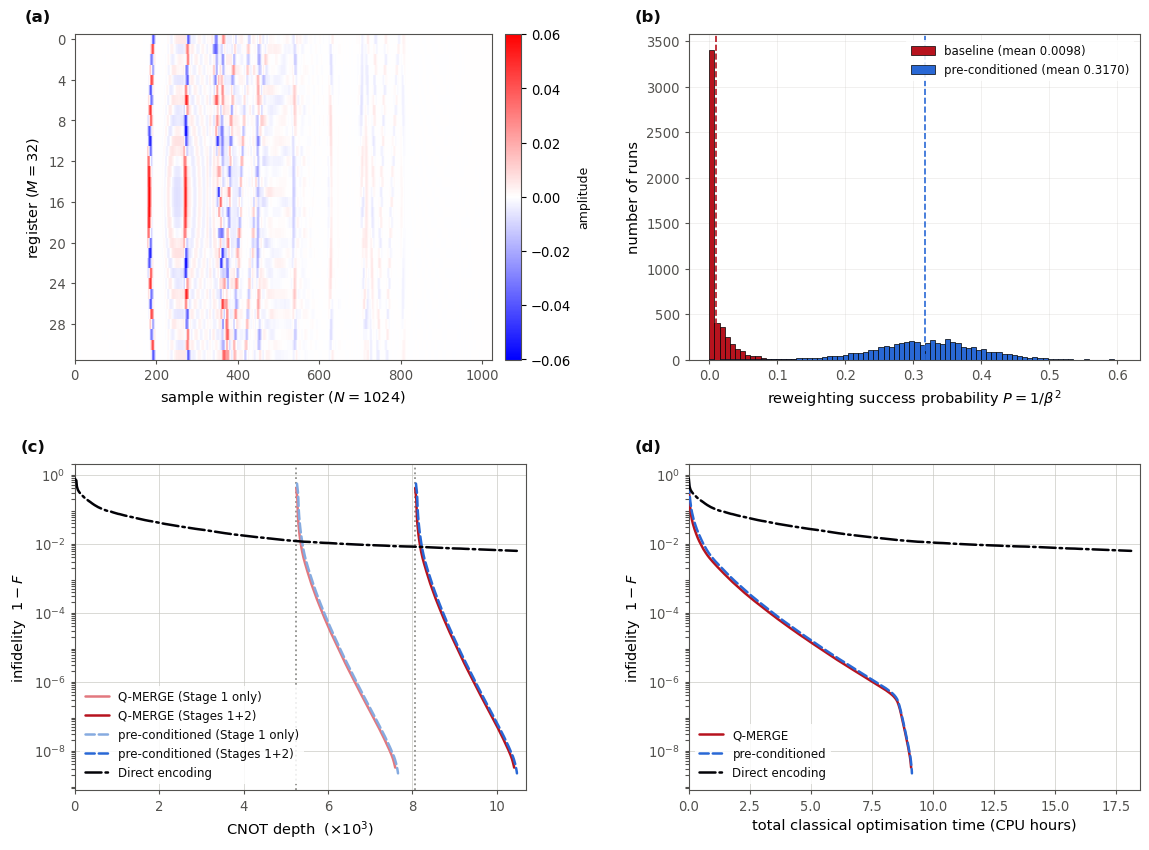

SAVED         fig_R75x4_collated_M32.pdf
TARGET        M = 32 x N = 1024   (rows 48..79 of 128)   ||Y|| = 1.000000
              Q-MERGE 336 qubits   direct 15 qubits
sigma_i       sum sigma^2 = 1.0000000000   min 0.1280  max 0.2307
------------------------------------------------------------------------------
(b) baseline  mean P = 0.0098 (converged, 100k shots)   median 0.00033   histogram from 5000 shots (own mean 0.0102 +/- 0.0003)
(b) 3 layers mean P = 0.3170 +/- 0.0011   median 0.32060   (5000 shots)   -> 32.3x for 18 CNOT depth
(b) IPR       4.5831e-05   (1.502x the uniform floor 3.052e-05)
------------------------------------------------------------------------------
STAGE 1       5,248   = M(24m + 8n - 36), SELECT-SWAP network
STAGE 2       2,816   = M(24m - 32), controlled rotations
STAGES 1+2    8,064   = M(48m + 8n - 68);  with V +18 -> 8,082
CUT           CNOT depth 10,473
------------------------------------------------------------------------------
Q-MERGE (Stage 1 only)

In [91]:
# ===== COLLATED FIGURE: the whole M = 32 story in one 2x2 panel =====
#   (a) the sub-dataset            (b) reweighting success
#   (c) infidelity vs CNOT depth   (d) infidelity vs CPU time
#
# This is the dataset cell, the success-histogram cell and the depth/time cell merged, with
# IDENTICAL data handling in each -- same sigma renormalisation, same BASE_MEAN, same
# CUT_TO_QMERGE, same FLOOR_TOL -- so the collated figure and the three standalone figures
# cannot disagree. Panels whose inputs are missing are left blank with a note rather than
# failing, so this works mid-campaign.
#
# ALL FOUR PANELS share the grid's natural aspect -- no set_box_aspect anywhere, so (b), (c)
# and (d) keep the proportions they have as standalone figures. Panel (a) is an imshow with
# aspect="auto", so it simply fills its cell; DATA_ASPECT flattens it if you want the image
# shorter than the plots. The true 32 x 1024 aspect is 0.03, unreadably thin, so the sample
# axis is compressed on purpose; the axis labels carry the real shape. Transposed relative to
# the paper's Fig. 3: register index runs vertically here.
#
# MERGE ACCOUNTING -- Jens's implementation, all in CNOT DEPTH:
#     m-controlled X : 2m-3 Toffolis (m-2 clean ancillas) = 12m - 18
#     Fredkin        : 8        rotation : 2 + controlled-Rz = 4
#   Stage 1, SELECT-SWAP compression (2 MCX + n Fredkins per segment) : M(24m + 8n - 36)
#   Stage 2, controlled rotations    (2 MCX + 1 rotation per segment) : M(24m - 32)
#   total merge                                                       : M(48m + 8n - 68)
#   For M=32, m=5, n=10: Stage 1 = 5,248   Stage 2 = 2,816   total = 8,064. V adds 6 L_V = 18.
#
# SEGMENT PREPARATION, L chi=2 staircase layers on n qubits:
#       prep_depth(n, L) = 3(n-1) + 6(L-1)
#   NOT 3(n-1)L -- the stack pipelines into a diagonal wavefront, so each layer past the first
#   adds exactly 2 SU(4) = 6, independent of n. Verified against pytket Circuit.depth():
#   n=10, L=379 -> 2295 = 3(9) + 6(378). The M registers are prepared IN PARALLEL (Alg. 1),
#   so Q-MERGE pays ONE register's depth; direct pays prep_depth(n_sub, L), n_sub = log2(M N).
import os, glob, json, math, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from skimage.transform import resize

BASE = os.getcwd()
TAG, FULL_M, FULL_N, n_row = "R75x4", 128, 1024, 10
M_SUB = 32
L_V   = 3            # brickwall pre-conditioning layers encoded (cell F1)

CUT_TO_QMERGE = True # crop every depth curve at Q-MERGE's deepest point, so direct ends
                     # exactly where Q-MERGE does and the plotted endpoints ARE the
                     # matched-depth comparison. Overrides CUT_CNOT.
CUT_CNOT  = None
FLOOR_TOL = 1e-10    # automatic cut once any row hits the double-precision floor

SHOW_L     = 3       # pre-conditioning depth shown in (b); None = best in file
NBINS      = 81
BASE_MEAN  = 0.0098  # converged baseline P, 100k shots (+/- 0.0001). The 5000-shot estimate
                     # stored in the pickle swings 0.0094-0.0102 because P is a skewed tail
                     # statistic (median ~3e-4 against mean ~1e-2).
CMAP        = "bwr"
FIGSIZE     = (11.6, 8.6)
DATA_ASPECT = None   # panel (a) height/width. None = fill the cell like the other three.
                     # Set e.g. 0.5 to make the data image shorter than the plots.

RATE_ANCHORS = [(0, 3.75), (220, 3.70), (240, 3.70), (250, 2.98), (270, 0.80),
                (290, 0.50), (370, 0.50), (400, 0.45)]
RATE_DIRECT  = {14: 13.0, 15: 37.5}

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"
RED_L, BLUE_L    = "#e2787f", "#86abe0"   # lighter shades for the Stage-1-only variants
GUIDE = "#8a8a86"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

def merge_stage1(N, M):
    m, n = int(math.log2(M)), int(math.log2(N))
    return M * (24 * m + 8 * n - 36)

def merge_stage2(M):
    return M * (24 * int(math.log2(M)) - 32)

def V_depth(L_V):
    """make_brick_wall_layer applies BOTH the even and odd sublayer per call, so one layer
    is 2 SU(4) deep = 6 CNOTs."""
    return 6 * L_V

def prep_depth(n, L):
    L = np.asarray(L)
    return np.where(L <= 0, 0, 3 * (n - 1) + 6 * np.maximum(L - 1, 0))

def cum_hours_rows(n_layers, M):
    xs = np.array([a for a, _ in RATE_ANCHORS], float)
    ys = np.array([r for _, r in RATE_ANCHORS], float)
    per_layer = np.interp(np.arange(1, n_layers + 1), xs, ys)
    return np.concatenate([[0.0], np.cumsum(per_layer)]) * M / 3600.0

# ---------------- shared target definition ----------------
ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))
n_sub    = int(round(np.log2(M_SUB * FULL_N)))
FLOOR_P  = 1.0 / 2 ** n_sub

_Y = resize(pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None).to_numpy(),
            (FULL_N, FULL_M), anti_aliasing=True)
_Y   = _Y / np.linalg.norm(_Y)
Y_sub = _Y[:, SUB_ROWS]; Y_sub = Y_sub / np.linalg.norm(Y_sub)
img   = Y_sub.T                                  # (32, 1024): rows = registers
_rn   = np.linalg.norm(Y_sub.T, axis=1); sigma_sub = _rn / np.linalg.norm(_rn)

def _subset_infid(run_name, rows, sigma):
    """1-F per layer over `rows`, truncated to the depth they ALL share, then cut before the
    double-precision floor.  F = (sum_i sigma_i^2 sqrt(F_i))^2."""
    path = os.path.join(BASE, "SSO results", f"row_sweep_{run_name}", "row_fids.json")
    if not os.path.exists(path):
        print(f"  [{run_name}] not started"); return None
    with open(path) as f:
        d = json.load(f)
    if any(str(i) not in d for i in rows):
        print(f"  [{run_name}] only {sum(str(i) in d for i in rows)}/{len(rows)} rows -- omitted")
        return None
    fids = [np.array(d[str(i)]["chi"]["2"]["chi_fids"], float) for i in rows]
    L = min(len(x) for x in fids)
    F = np.clip(np.array([x[:L] for x in fids]), 0.0, 1.0)
    worst = (1.0 - F).min(axis=0)
    ok = np.flatnonzero(worst > FLOOR_TOL)
    if ok.size and ok[-1] + 1 < F.shape[1]:
        print(f"  [{run_name}] numerical floor from depth {ok[-1]+1} -- cut there")
        F = F[:, :ok[-1] + 1]
    print(f"  [{run_name}] {len(rows)} rows, using depth 0..{F.shape[1]-1}")
    amp = (sigma[:, None] ** 2 * np.sqrt(F)).sum(axis=0)
    return np.clip(1.0 - np.clip(amp ** 2, 0.0, 1.0), 1e-16, None)

s1      = merge_stage1(FULL_N, M_SUB)      # SELECT-SWAP network   (Stage 1)
s12     = s1 + merge_stage2(M_SUB)         # + reweighting block   (Stages 1+2)
_vd     = V_depth(L_V)
s1_pre, s12_pre = s1 + _vd, s12 + _vd
rate_D  = RATE_DIRECT[n_sub]
KD = 1e-3

# ---------------- (c)/(d) curves: (x_depth, x_time, y, colour, style, label) ----------------
LINES = {}

infid_Q = _subset_infid(f"{TAG}_orig", SUB_ROWS, sigma_sub)
if infid_Q is not None:
    _t = cum_hours_rows(len(infid_Q) - 1, M_SUB)
    _d = prep_depth(n_row, np.arange(len(infid_Q)))
    LINES["qmerge_s1"] = (s1  + _d, _t, infid_Q, RED_L, "-", "Q-MERGE (Stage 1 only)")
    LINES["qmerge"]    = (s12 + _d, _t, infid_Q, RED,   "-", "Q-MERGE (Stages 1+2)")

_pre_run = f"{TAG}_M{M_SUB}_precond_L{L_V}"
_pre_sig = os.path.join(BASE, "SSO results", f"row_sweep_{_pre_run}", "sigma.npy")
if os.path.exists(_pre_sig):
    infid_B = _subset_infid(_pre_run, list(range(M_SUB)), np.load(_pre_sig))
    if infid_B is not None:
        _t = cum_hours_rows(len(infid_B) - 1, M_SUB)
        _d = prep_depth(n_row, np.arange(len(infid_B)))
        LINES["precond_s1"] = (s1_pre  + _d, _t, infid_B, BLUE_L, "--",
                               "pre-conditioned (Stage 1 only)")
        LINES["precond"]    = (s12_pre + _d, _t, infid_B, BLUE,   "--",
                               "pre-conditioned (Stages 1+2)")
else:
    print(f"  [{_pre_run}] not started -- run cell F1")

SUB_CKPT = os.path.join(BASE, "SSO results", f"fullstate_{TAG}_M{M_SUB}", "checkpoint.npz")
if os.path.exists(SUB_CKPT):
    with np.load(SUB_CKPT) as ck:
        assert int(ck["M_sub"]) == M_SUB, f"checkpoint is M_sub={int(ck['M_sub'])}"
        yD = np.clip(1.0 - np.array(ck["chi_fids"], float), 1e-16, None)
    LINES["direct"] = (prep_depth(n_sub, np.arange(len(yD))),
                       np.arange(len(yD)) * rate_D / 3600.0,
                       yD, BLACK, "-.", "Direct encoding")
    print(f"  [direct M{M_SUB}] {len(yD)-1} layers")
else:
    print(f"  [direct] no checkpoint at {SUB_CKPT}")

if CUT_TO_QMERGE and LINES:
    _ends = [LINES[k][0][-1] for k in ("qmerge", "precond") if k in LINES]
    if _ends:
        CUT_CNOT = int(max(_ends))
        print(f"  cutting every curve at Q-MERGE's deepest point: {CUT_CNOT:,}")

if CUT_CNOT is not None:
    for k, (xd, xt, y, c, ls, lab) in list(LINES.items()):
        keep = xd <= CUT_CNOT
        if keep.sum() == 0:
            raise ValueError(f"CUT_CNOT = {CUT_CNOT:,} removes the whole '{lab}' curve, "
                             f"which starts at depth {xd[0]:,.0f}. Raise it above that.")
        if keep.sum() < len(xd):
            print(f"  [{lab}] cropped to CNOT depth {CUT_CNOT:,}: "
                  f"{keep.sum()-1} layers of {len(xd)-1}")
        LINES[k] = (xd[keep], xt[:keep.sum()], y[keep], c, ls, lab)

# ---------------- (b) reweighting success ----------------
HIST = None
_paths = sorted(glob.glob(os.path.join(BASE, "results", f"v_{TAG}_M{M_SUB}_*.pkl")))
_cands = []
for p in _paths:
    with open(p, "rb") as f:
        _d = pickle.load(f)
    for L, r in _d.get("layer_results", {}).items():
        _cands.append((r["res"]["mean"], L, p, _d))
if not _cands:
    print(f"  [success] no completed layers in results/v_{TAG}_M{M_SUB}_*.pkl -- run cell E1")
else:
    _sel = _cands if SHOW_L is None else [c for c in _cands if c[1] == SHOW_L]
    assert _sel, f"no file contains layer {SHOW_L}"
    _bP, _bL, _bpath, _bdata = max(_sel, key=lambda t: t[0])
    _r = _bdata["layer_results"][_bL]
    assert _r["ipr"] / FLOOR_P > 1.05, (
        f"layer {_bL} sits on the uniform IPR floor ({_r['ipr']/FLOOR_P:.4f}x) -- the "
        f"non-unitary-V signature. Delete {os.path.basename(_bpath)} and re-run E1.")
    P0, P1 = np.asarray(_bdata["base_result"]["P"]), np.asarray(_r["res"]["P"])
    HIST = (P0, BASE_MEAN, P1, _r["res"]["mean"], _bL, _bpath, _r["ipr"], _bdata)
    print(f"  [success] {os.path.basename(_bpath)}, layer {_bL}: "
          f"P {BASE_MEAN:.4f} -> {_r['res']['mean']:.4f}")

# ================================ draw ================================
with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 8.5}):
    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE)
    (axA, axB), (axC, axD) = axes

    # ---- (a) the sub-dataset ----
    vmax = np.abs(img).max()        # symmetric limits so white sits exactly at zero amplitude
    im = axA.imshow(img, aspect="auto", cmap=CMAP, interpolation="nearest",
                    vmin=-vmax, vmax=vmax)
    axA.set_xlabel(f"sample within register ($N = {FULL_N}$)")
    axA.set_ylabel(f"register ($M = {M_SUB}$)")
    axA.set_yticks(range(0, M_SUB, 4))
    if DATA_ASPECT is not None:
        axA.set_box_aspect(DATA_ASPECT)
    cb = fig.colorbar(im, ax=axA, fraction=0.046, pad=0.03)
    cb.outline.set_edgecolor(MUTED); cb.set_label("amplitude", fontsize=9, color=INK)
    for s in axA.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    axA.tick_params(colors=MUTED, which="both", length=3, width=0.8)

    # ---- (b) reweighting success ----
    if HIST is None:
        axB.text(0.5, 0.5, "no reweighting run on disk\n(run cell E1)", ha="center",
                 va="center", transform=axB.transAxes, color=MUTED, fontsize=9)
        axB.set_xticks([]); axB.set_yticks([])
    else:
        P0, m0, P1, m1, _bL, _bpath, _ipr, _bdata = HIST
        bins = np.linspace(min(P0.min(), P1.min()), max(P0.max(), P1.max()) * 1.02, NBINS)
        axB.grid(alpha=0.3, zorder=0, lw=0.6, color=GRID)
        for P, mean, c, lab in ((P0, m0, RED,  f"baseline (mean {m0:.4f})"),
                                (P1, m1, BLUE, f"pre-conditioned (mean {m1:.4f})")):
            axB.hist(P, bins=bins, color=c, edgecolor="black", lw=0.5, label=lab, zorder=2)
            axB.axvline(mean, color=c, ls="--", lw=1.2, zorder=3)
        axB.set_xlabel(r"reweighting success probability $P = 1/\beta^2$")
        axB.set_ylabel("number of runs")
        style_legend(axB, loc="upper right")
    tidy(axB)

    # ---- (c) depth and (d) CPU time ----
    for _g in (s1, s12):            # upfront merge cost: Stage 1, then Stages 1+2
        axC.axvline(_g * KD, color=GUIDE, ls=":", lw=1.3, alpha=0.95, zorder=1)
    axC.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
    axD.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)

    # (c) shows all four Q-MERGE variants; (d) only Stages 1+2 -- the Stage-1-only curves are
    # the SAME optimisation runs and would overlay exactly on a time axis.
    for k in ("qmerge_s1", "qmerge", "precond_s1", "precond", "direct"):
        if k not in LINES: continue
        xd, xt, y, c, ls, lab = LINES[k]
        axC.semilogy(xd * KD, y, ls=ls, lw=1.8, color=c, label=lab,
                     solid_capstyle="round", dash_capstyle="round", zorder=3)
        if k.endswith("_s1"): continue
        axD.semilogy(xt, y, ls=ls, lw=1.8, color=c, label=lab.replace(" (Stages 1+2)", ""),
                     solid_capstyle="round", dash_capstyle="round", zorder=3)

    if LINES:
        XMAX_D = max(v[0][-1] for v in LINES.values()) * KD * 1.02
        XMAX_T = max(v[1][-1] for v in LINES.values()) * 1.02
        YMIN   = min(v[2].min() for v in LINES.values()) / 3.0
    else:
        for ax in (axC, axD):
            ax.text(0.5, 0.5, "no SSO sweeps on disk", ha="center", va="center",
                    transform=ax.transAxes, color=MUTED, fontsize=9)
        XMAX_D, XMAX_T, YMIN = 1, 1, 1e-9

    axC.set_xlabel(r"CNOT depth  ($\times 10^{3}$)")
    axD.set_xlabel("total classical optimisation time (CPU hours)")
    for ax, xmax in ((axC, XMAX_D), (axD, XMAX_T)):
        ax.set_ylabel(r"infidelity  $1-F$")
        ax.set_xlim(0, xmax); ax.set_ylim(YMIN, 2.0)
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1,
                                              numticks=20))
        ax.yaxis.set_minor_formatter(NullFormatter())
        if LINES: style_legend(ax, loc="lower left")
        tidy(ax)

    for ax, tag in ((axA, "(a)"), (axB, "(b)"), (axC, "(c)"), (axD, "(d)")):
        ax.text(-0.12, 1.03, tag, transform=ax.transAxes, fontsize=12,
                fontweight="bold", color=INK, va="bottom", ha="left")

    fig.tight_layout(w_pad=2.6, h_pad=2.2)
    OUT = os.path.join(BASE, f"fig_{TAG}_collated_M{M_SUB}.pdf")
    fig.savefig(OUT, bbox_inches="tight")
    plt.show()

# ================================ numbers ================================
print("=" * 78)
print(f"SAVED         {os.path.basename(OUT)}")
print(f"TARGET        M = {M_SUB} x N = {FULL_N}   (rows {SUB_ROWS[0]}..{SUB_ROWS[-1]} "
      f"of {FULL_M})   ||Y|| = {np.linalg.norm(Y_sub):.6f}")
print(f"              Q-MERGE {M_SUB*n_row + n_row + int(math.log2(M_SUB)) + 1} qubits   "
      f"direct {n_sub} qubits")
print(f"sigma_i       sum sigma^2 = {(sigma_sub**2).sum():.10f}   "
      f"min {sigma_sub.min():.4f}  max {sigma_sub.max():.4f}")
print("-" * 78)
if HIST is not None:
    P0, m0, P1, m1, _bL, _bpath, _ipr, _bdata = HIST
    _s0 = P0.std(ddof=1) / np.sqrt(len(P0)); _s1 = P1.std(ddof=1) / np.sqrt(len(P1))
    print(f"(b) baseline  mean P = {m0:.4f} (converged, 100k shots)   "
          f"median {np.median(P0):.5f}   histogram from {len(P0)} shots "
          f"(own mean {_bdata['base_result']['mean']:.4f} +/- {_s0:.4f})")
    print(f"(b) {_bL} layers mean P = {m1:.4f} +/- {_s1:.4f}   median {np.median(P1):.5f}   "
          f"({len(P1)} shots)   -> {m1/m0:.1f}x for {6*_bL} CNOT depth")
    print(f"(b) IPR       {_ipr:.4e}   ({_ipr/FLOOR_P:.3f}x the uniform floor {FLOOR_P:.3e})")
    print("-" * 78)
print(f"STAGE 1       {s1:,}   = M(24m + 8n - 36), SELECT-SWAP network")
print(f"STAGE 2       {merge_stage2(M_SUB):,}   = M(24m - 32), controlled rotations")
print(f"STAGES 1+2    {s12:,}   = M(48m + 8n - 68);  with V +{_vd} -> {s12_pre:,}")
print(f"CUT           CNOT depth {CUT_CNOT:,}" if CUT_CNOT else "CUT           none")
print("-" * 78)
for k in ("qmerge_s1", "qmerge", "precond_s1", "precond", "direct"):
    if k not in LINES: continue
    xd, xt, y, c, ls, lab = LINES[k]
    print(f"{lab:<34} {len(y)-1:>4d} layers   depth {xd[-1]:>7,.0f}   "
          f"CPU {xt[-1]:>5.2f} h   1-F = {y[-1]:.3e}")
if "qmerge" in LINES and "direct" in LINES:
    xq, _, yq, *_ = LINES["qmerge"]; xdd, _, yd, *_ = LINES["direct"]
    dmax = min(xq[-1], xdd[-1])
    q  = yq[max(np.searchsorted(xq, dmax) - 1, 0)]
    dd = yd[max(np.searchsorted(xdd, dmax) - 1, 0)]
    print(f"at matched depth {dmax:,.0f}:  Q-MERGE {q:.3e}  vs  direct {dd:.3e}  ({dd/q:,.0f}x)")
print("=" * 78)



## Fig. 4 and Table I -- shadow-overlap certification on Quantinuum H2-1

The 53-qubit Stage-1 run: 4 preparation registers of 10 qubits, a 10-qubit storage
register, 2 index qubits and 1 ancilla, with each segment prepared by a deliberately
shallow 1-layer SSO circuit so the noise budget is dominated by Q-MERGE itself.

Top row is the noiseless circuit simulation, middle row the H2-1 hardware shots, bottom
row the inverse linear regression that turns each measured shadow overlap into a fidelity
estimate with a 90% interval. The reference state is what the circuit itself prepares for
each branch, so the quoted fidelity is hardware degradation with the deliberately-lossy
1-layer encoding error factored out.

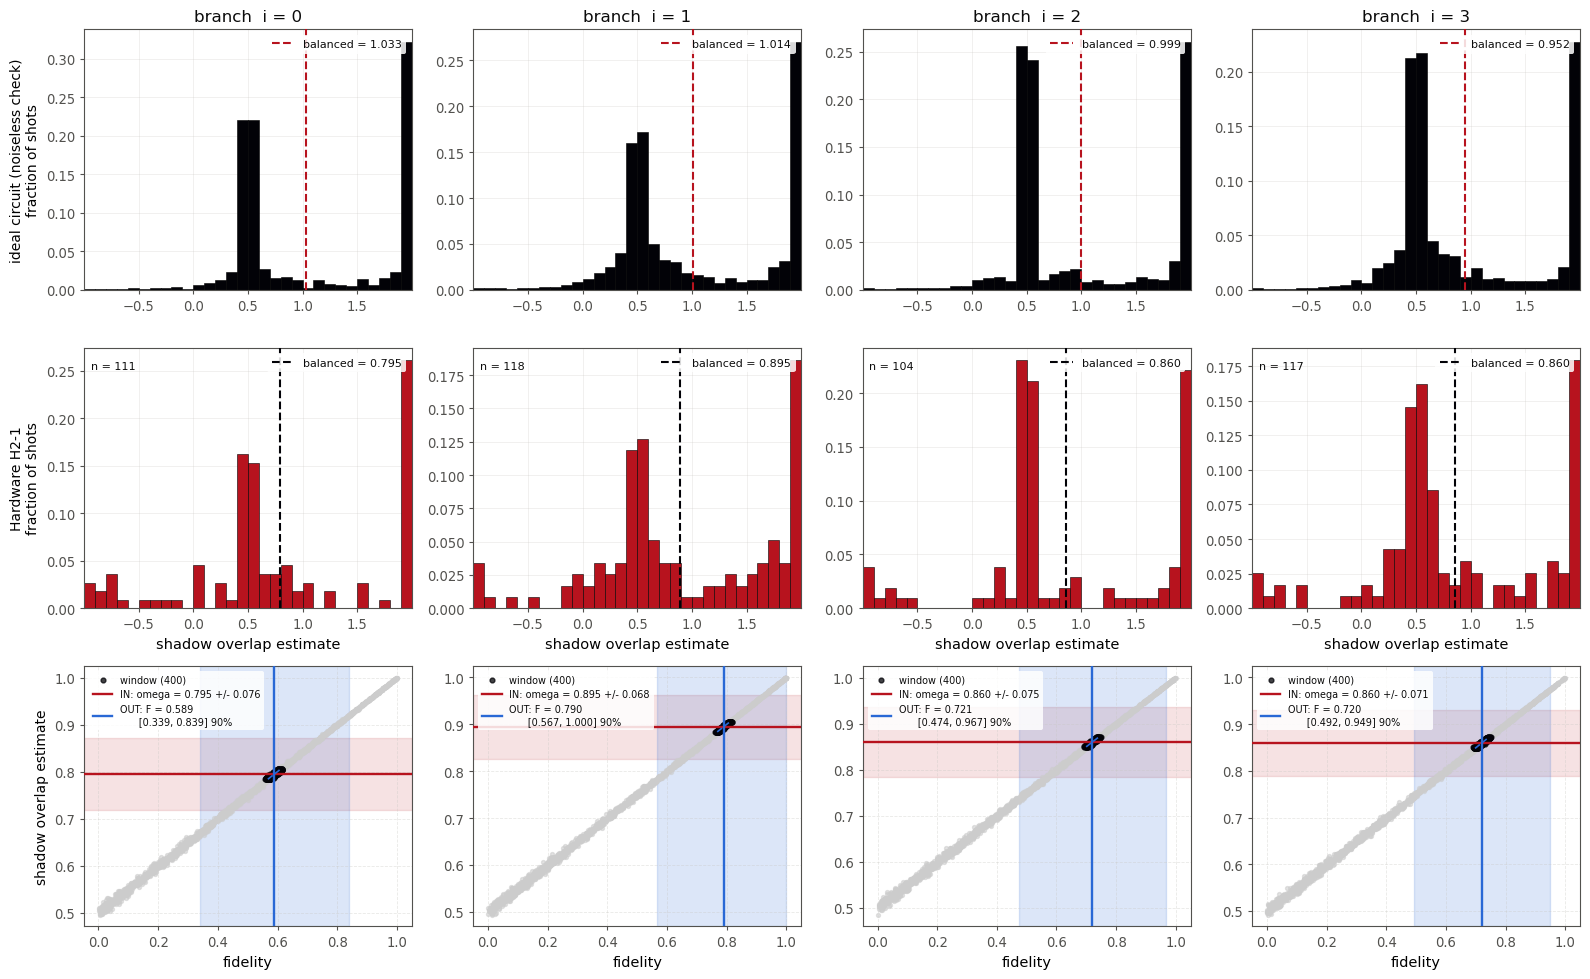

calibration points per branch: 9000   drawn: 1500 + 400 window (rasterised)
branch 0: omega 0.795 +/- 0.076  ->  F = 0.589  [0.339, 0.839] 90%  (vs ideal circuit output)
branch 1: omega 0.895 +/- 0.068  ->  F = 0.790  [0.567, 1.000] 90%  (vs ideal circuit output)
branch 2: omega 0.860 +/- 0.075  ->  F = 0.721  [0.474, 0.967] 90%  (vs ideal circuit output)
branch 3: omega 0.860 +/- 0.071  ->  F = 0.720  [0.492, 0.949] 90%  (vs ideal circuit output)


In [89]:
# SOURCE: ShadowOverlapMultiregister.ipynb, cell 78 ("STORAGE-REGISTER SHADOW OVERLAP, PER
#         INDEX BRANCH (4x1024_L1_mid)"), restyled to this notebook's report style and made
#         light enough to open quickly.
#
# This is the UPSCALED (4 x 1024, 53-qubit) hardware run -- Fig. 5 and Table I of the paper.
# The other Fig. 5 cell in this notebook is the 4x32 / 28-qubit run; both are kept.
#
# WHY IT USED TO BE SLOW: the bottom row drew the full calibration cloud as vector points --
# 9000 per branch x 4 branches = 36,000 individual PDF path objects, which is what makes the
# viewer crawl. Two fixes, both display-only:
#   SHOW_N        -- draw a random subsample of the out-of-window cloud (the FIT still uses
#                    every one of the 9000 points; nothing numerical changes, see below).
#   rasterized    -- the scatter layers are rasterised at SCATTER_DPI, so they become one
#                    small image per panel instead of thousands of paths. Text, axes, lines
#                    and the regression fit stay vector/selectable.
# The window points (the K_NEIGHBOURS actually used by the local fit) are NEVER subsampled --
# they are the evidence for the quoted number, so they are all drawn.
#
# Reads off disk, nothing upstream needs re-running:
#   shadow_branch_hw_4x1024_L1_mid.pkl                      <- branch-resolved hardware shots
#   shadow_vs_fidelity_rows_4x1024_L1_mid_vs_ideal.npz      <- calibration curve, 9000 pts/branch
#   mre_prep_circuits_4x1024_L1_mid.qpy                     <- the per-branch IDEAL reference
#
# The reference is IDEAL[i] = what the circuit itself prepares for branch i, NOT the raw target
# row, so the fidelity reported is hardware degradation with the deliberately-lossy 1-layer SSO
# encoding error factored out. X, Y and Z are all genuinely measured here (no analytic-Y
# shortcut, since IDEAL is not real-valued the way the raw rows were).
import os, random, pickle
import numpy as np
import matplotlib.pyplot as plt
from qiskit import qpy
from qiskit.quantum_info import Statevector

BASE = os.getcwd()
TAG  = "4x1024_L1_mid"

SHOW_N      = 1500     # out-of-window calibration points DRAWN per panel (of 9000). None = all.
SCATTER_DPI = 220      # rasterisation dpi for the point clouds
PLOT_SEED   = 0        # which subsample you get; fixed so the figure is reproducible

# ---- shared report style (identical block in every figure cell in this notebook) ----
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

PAULIS = ["X", "Y", "Z"]
NBINS  = 30
BR_STORE  = os.path.join(BASE, f"shadow_branch_hw_{TAG}.pkl")
ROWS_FILE = os.path.join(BASE, f"shadow_vs_fidelity_rows_{TAG}_vs_ideal.npz")
Z_ASSIGN_SEED, SIM_SEED, SIM_REPS = 11, 2026, 200
CONF, K_NEIGHBOURS, USE, N_MC, MC_SEED = 0.90, 400, "exact", 200_000, 0
NO_SUPPORT_TOL = 1e-12

prep_circuits = qpy.load(open(os.path.join(BASE, f"mre_prep_circuits_{TAG}.qpy"), "rb"))
IDEAL   = [np.asarray(Statevector(c)) for c in prep_circuits]
CHUNKS  = [np.asarray(c, dtype=complex) / np.linalg.norm(c) for c in IDEAL]
N_S, M_BRANCH = prep_circuits[0].num_qubits, len(prep_circuits)
S_QUBITS = tuple(range(N_S))
assert len(CHUNKS[0]) == 2 ** N_S

def rotated_outcome_to_zket(outcome, pauli):
    if pauli == "Z":
        return np.array([1, 0], dtype=complex) if outcome == 0 else np.array([0, 1], dtype=complex)
    if pauli == "X":
        return np.array([1, 1], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    if pauli == "Y":
        return np.array([1, 1j], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    raise ValueError(f"Pauli must be X, Y or Z, got {pauli!r}")

def compute_local_overlap(cond, outcome, P):
    """omega = <phi| (3|s><s| - I) |phi>  for a single-qubit conditional state."""
    s = rotated_outcome_to_zket(outcome, P)
    O3 = 3 * np.outer(s, s.conj()) - np.eye(2, dtype=complex)
    return np.vdot(np.asarray(cond, dtype=complex), O3 @ np.asarray(cond, dtype=complex)).real

_no_support = {"n": 0}
def omega(chunk, sb, q, p, tol=NO_SUPPORT_TOL):
    """One shadow-overlap estimate. The no-support guard MUST be a tolerance, not `== 0`:
    ideally-vanishing amplitudes are stored as ~1e-16, never exactly zero."""
    pos = N_S - 1 - q
    z, o = sb[:pos] + "0" + sb[pos+1:], sb[:pos] + "1" + sb[pos+1:]
    v = np.array([chunk[int(z, 2)], chunk[int(o, 2)]], dtype=complex)
    nv = np.linalg.norm(v)
    if nv < tol:
        _no_support["n"] += 1; return 0.0
    return compute_local_overlap(v / nv, int(sb[pos]), PAULIS[p])

def storage_shots(store, seed=Z_ASSIGN_SEED):
    """X and Y are both real hardware shots here; Z is the shared prep/ancilla-targeted bank."""
    recs = []
    for (q, p), d in store["xy"].items():
        for k, c in d.items():
            i, sb = k.split(":")
            recs += [(sb, int(i), q, p)] * c
    zs = [(k.split(":")[1], int(k.split(":")[0])) for k, c in store["z_pool"].items() for _ in range(c)]
    random.Random(seed).shuffle(zs)
    recs += [(sb, i, S_QUBITS[j % N_S], 2) for j, (sb, i) in enumerate(zs)]
    return recs

_H, _Sdg = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1j]).astype(complex)
def _rot_probs(vec, q, p):
    if p == 2: return np.abs(vec) ** 2
    U = _H if p == 0 else _H @ _Sdg
    v3 = vec.reshape(-1, 2, 2 ** q); b0, b1 = v3[:, 0, :], v3[:, 1, :]
    out = np.empty_like(v3)
    out[:, 0, :], out[:, 1, :] = U[0,0]*b0 + U[0,1]*b1, U[1,0]*b0 + U[1,1]*b1
    return np.abs(out.reshape(-1)) ** 2

def sim_like(recs, reps=SIM_REPS, seed=SIM_SEED):
    """Noiseless reference matched cell-for-cell to `recs`: same (branch, qubit, Pauli)
    design, only the outcome bits resampled from the ideal state."""
    rng, cdfs, out = np.random.default_rng(seed), {}, []
    for _, i, q, p in recs:
        if (i, q, p) not in cdfs:
            cdfs[(i, q, p)] = np.cumsum(_rot_probs(CHUNKS[i], q, p))
        cdf = cdfs[(i, q, p)]
        idx = np.minimum(np.searchsorted(cdf, rng.random(reps)), len(cdf) - 1)
        out += [(np.binary_repr(int(j), width=N_S), i, q, p) for j in idx]
    return out

def evaluate(recs):
    _no_support["n"] = 0
    est = np.array([omega(CHUNKS[i], sb, q, p) for sb, i, q, p in recs])
    return est, np.array([i for _, i, _, _ in recs]), np.array([p for *_, p in recs])

def pauli_var(est, pau):
    return {p: float(est[pau == p].var(ddof=1)) for p in range(3) if (pau == p).sum() > 1}

def balanced(est, pau, var_ref=None):
    """Uniform-design (X,Y,Z) mean and its SE -- all three strata genuinely measured."""
    ms, vs = [], []
    for p in range(3):
        v = est[pau == p]
        if len(v) == 0: return float("nan"), float("nan")
        ms.append(v.mean())
        s2 = v.var(ddof=1) if len(v) > 1 else (var_ref or {}).get(p, np.nan)
        vs.append(s2 / len(v))
    return float(np.mean(ms)), float(np.sqrt(np.nansum(vs)) / 3)

def invert(F, w, omega_star, k):
    sel = np.argsort(np.abs(w - omega_star))[:min(k, len(w))]
    ww, ff = w[sel] - omega_star, F[sel]
    b, a = np.polyfit(ww, ff, 1)
    return dict(a=a, b=b, resid=ff - (a + b * ww), sel=sel,
                lo=w[sel].min(), hi=w[sel].max(), n=len(sel))

def predict(fit, omega_star, omega_se, conf, rng, n=N_MC):
    draws = rng.normal(omega_star, omega_se, n) if omega_se else np.full(n, omega_star)
    vals  = fit["a"] + fit["b"] * (draws - omega_star) + rng.choice(fit["resid"], n)
    lo, hi = np.percentile(vals, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return float(np.clip(lo, 0, 1)), float(np.clip(hi, 0, 1))

with open(BR_STORE, "rb") as f:
    hw_recs = storage_shots(pickle.load(f))
rows = [("ideal circuit (noiseless check)", BLACK, RED,  sim_like(hw_recs)),
        ("Hardware H2-1",                   RED,   BLACK, hw_recs)]
data = []
for label, fill, meanc, recs in rows:
    est, br, pau = evaluate(recs)
    data.append((label, fill, meanc, est, br, pau, pauli_var(est, pau)))
with np.load(ROWS_FILE) as _z:
    z = {k: _z[k] for k in _z.files}

edges = np.linspace(min(d[3].min() for d in data), max(d[3].max() for d in data), NBINS + 1)

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 8}):
    fig, axes = plt.subplots(3, M_BRANCH, figsize=(4.0 * M_BRANCH, 3.3 * 3), squeeze=False)

    for r, (label, fill, meanc, est, br, pau, vref) in enumerate(data):
        for i in range(M_BRANCH):
            ax, v, p = axes[r, i], est[br == i], pau[br == i]
            if len(v):
                ax.hist(v, bins=edges, weights=np.full(len(v), 1 / len(v)),
                        color=fill, edgecolor="black", lw=0.4, zorder=2)
                m, s = balanced(v, p, vref)
                ax.axvline(m, color=meanc, ls="--", lw=1.5, zorder=3,
                           label=f"balanced = {m:.3f}")
                if label == "Hardware H2-1":
                    ax.text(0.02, 0.95, f"n = {len(v)}", transform=ax.transAxes,
                            va="top", fontsize=8, color=INK)
                style_legend(ax, loc="upper right")
            ax.set_xlim(edges[0], edges[-1])
            ax.grid(alpha=0.3, lw=0.6, color=GRID)
            if r == 0: ax.set_title(f"branch  i = {i}", fontsize=12, color=INK)
            else:      ax.set_xlabel("shadow overlap estimate")
            tidy(ax)
        axes[r, 0].set_ylabel(f"{label}\nfraction of shots", fontsize=10)

    _, _, _, est, br, pau, vref = data[1]
    rng, results = np.random.default_rng(MC_SEED), {}
    plot_rng = np.random.default_rng(PLOT_SEED)
    for i in range(M_BRANCH):
        ax = axes[2, i]
        omega_star, omega_se = balanced(est[br == i], pau[br == i], vref)
        w, F = z[f"row{i}_{USE}"], z[f"row{i}_fid"]
        if omega_star != omega_star:
            ax.text(0.5, 0.5, "no estimate yet", transform=ax.transAxes, ha="center"); continue

        fit = invert(F, w, omega_star, K_NEIGHBOURS)      # <- uses ALL 9000 points
        lo, hi = predict(fit, omega_star, omega_se, CONF, rng)
        results[i] = (omega_star, omega_se, fit, lo, hi)

        inside = np.zeros(len(w), bool); inside[fit["sel"]] = True
        out_idx = np.flatnonzero(~inside)
        if SHOW_N is not None and len(out_idx) > SHOW_N:    # DISPLAY ONLY -- fit unaffected
            out_idx = plot_rng.choice(out_idx, SHOW_N, replace=False)
        ax.scatter(F[out_idx], w[out_idx], color="#cccccc", alpha=0.55, s=8,
                   rasterized=True, zorder=1)
        ax.scatter(F[inside], w[inside], color=BLACK, alpha=0.75, s=12,
                   rasterized=True, zorder=2, label=f"window ({fit['n']})")

        ax.axhspan(omega_star - omega_se, omega_star + omega_se, color=RED, alpha=0.12, zorder=0)
        ax.axhline(omega_star, color=RED, lw=1.7, zorder=3,
                   label=f"IN: omega = {omega_star:.3f} +/- {omega_se:.3f}")
        ax.axvspan(lo, hi, color=BLUE, alpha=0.16, zorder=0)
        ax.axvline(fit["a"], color=BLUE, lw=1.7, zorder=3,
                   label=f"OUT: F = {fit['a']:.3f}\n      [{lo:.3f}, {hi:.3f}] {CONF:.0%}")
        xs = np.linspace(fit["lo"], fit["hi"], 50)
        ax.plot(fit["a"] + fit["b"] * (xs - omega_star), xs, color=BLUE, ls="--", lw=1.2, zorder=3)
        ax.set_xlabel("fidelity")
        ax.grid(True, ls="--", alpha=0.4, lw=0.6, color=GRID)
        style_legend(ax, loc="upper left", fontsize=7)
        tidy(ax)
    axes[2, 0].set_ylabel("shadow overlap estimate", fontsize=10)

    fig.tight_layout()
    fig.savefig(os.path.join(BASE, f"fig_hardware_{TAG}.pdf"),
                bbox_inches="tight", dpi=SCATTER_DPI)
    plt.show()

print(f"calibration points per branch: {len(z['row0_fid'])}   "
      f"drawn: {SHOW_N if SHOW_N else 'all'} + {K_NEIGHBOURS} window (rasterised)")
for i in sorted(results):
    om, se, fit, lo, hi = results[i]
    print(f"branch {i}: omega {om:.3f} +/- {se:.3f}  ->  F = {fit['a']:.3f}  "
          f"[{lo:.3f}, {hi:.3f}] {CONF:.0%}  (vs ideal circuit output)")


## Fig. 5 -- scaling of the reweighting success probability

Stage-2 success probability *P* = 1/beta^2 against the number of segments *M*, for
Haar-random segments at three segment lengths *N*. *P* is independent of *N* and decays
only slowly with *M*, staying above 5% out to *M* = 10^7.

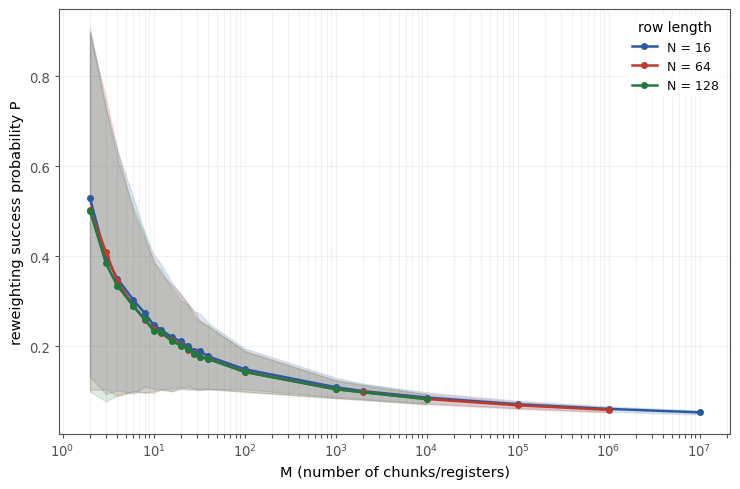


     N   M (largest tested)     P_mean      P_p10      P_p90
    16             10000000 5.2992e-02 4.8258e-02 5.7075e-02
    64              1000000 5.8703e-02 5.2906e-02 6.4016e-02
   128                10000 8.2335e-02 7.0767e-02 9.3462e-02


In [6]:
# SOURCE: "Reweighting Success Probability vs M N.ipynb", cell 1 (LINE_COLORS)
#         + cell 12 (runs/loads the sweep into sweep_success_prob_vs_M.csv)
#         + cell 13 (the plot itself).
# Reads the already-finished sweep off disk (1500 trials per (M, N) point, M up to 1e7):
#   sweep_success_prob_vs_M.csv
# To extend the grid (larger M, or a new N), go re-run the sweep in that notebook -- it
# appends to the same CSV and skips (M, N) points already done -- then just re-run this cell.
#
# No chart title (caption lives in LaTeX). These line colors encode a different variable
# (row length N) from the red/blue/black preconditioning comparison used in Figs. 3 & 4 above,
# so they keep their own categorical palette.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = os.getcwd()

# ---- shared report style (identical block in every figure cell in this notebook) ----
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

RED, BLUE, GREEN, GREY, BLACK = '#c0392b', '#2c5aa0', '#1f7a3f', '#7f8c8d', '#111111'
LINE_COLORS = [BLUE, RED, GREEN, GREY, BLACK]   # fixed categorical order for multi-line plots

N_values_1 = [16, 64, 128]
N_TRIALS_1 = 1500          # trials/point used when sweep_success_prob_vs_M.csv was generated

df_M = pd.read_csv(os.path.join(BASE, "sweep_success_prob_vs_M.csv"))

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for N, color in zip(N_values_1, LINE_COLORS):
        sub = df_M[df_M.N == N].sort_values("M")
        ax.plot(sub.M, sub.P_mean, color=color, marker='o', ms=4, lw=1.8, label=f"N = {N}")
        ax.fill_between(sub.M, sub.P_p10, sub.P_p90, color=color, alpha=0.15)

    ax.set_xscale("log")
    ax.set_xlabel("M (number of chunks/registers)")
    ax.set_ylabel("reweighting success probability P")
    style_legend(ax, title="row length")
    ax.grid(alpha=0.25, which='both', color=GRID)
    tidy(ax)
    plt.tight_layout()
    fig.savefig(os.path.join(BASE, "sweep_P_vs_M.pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(BASE, "sweep_P_vs_M.png"), dpi=130)
    plt.show()

print(f"\n{'N':>6s} {'M (largest tested)':>20s} {'P_mean':>10s} {'P_p10':>10s} {'P_p90':>10s}")
for N in N_values_1:
    sub = df_M[df_M.N == N].sort_values("M")
    last = sub.iloc[-1]
    print(f"{N:>6d} {int(last.M):>20d} {last.P_mean:>10.4e} {last.P_p10:>10.4e} {last.P_p90:>10.4e}")
